# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

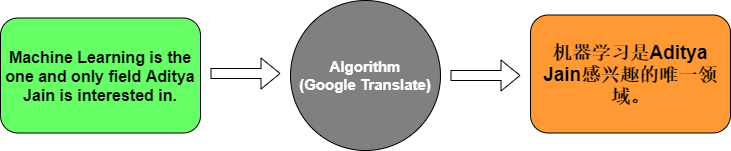

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


Embedding layer: it turns each word index into a dense vector of 64 numbers. Similar words can end up with similar vectors, and the model learns these vectors during training. Without it the model would only see meaningless integers.


Encoder LSTM: it reads the English sentence word by word and compresses the whole sentence into one fixed-size vector (64 numbers) that holds its meaning.

Decoder LSTM: it takes that sentence vector (repeated once per French position by RepeatVector) and produces an output at each step, one for each position of the French sentence.

Softmax in the final layer: it turns the scores for every French word into probabilities that sum to 1, so at each position we can pick the word with the highest probability. It also fits sparse_categorical_crossentropy, the loss we use.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [1]:
import pandas as pd

df = pd.read_csv('eng_-french.csv')
df.columns = ['english', 'french']
df['english'] = df['english'].str.lower()
df['french'] = df['french'].str.lower()

print(df.shape)
df.head()

(175621, 2)


,english,french
0,hi.,salut!
1,run!,cours !
2,run!,courez !
3,who?,qui ?
4,wow!,ça alors !


In [10]:
short = df[(df['english'].str.split().str.len() <= 5) & (df['french'].str.split().str.len() <= 6)]
data = short.sample(10000, random_state=42)

english_sentences = data['english'].tolist()
french_sentences = data['french'].tolist()

print(len(english_sentences))
print(english_sentences[0], '->', french_sentences[0])

10000
i'm always under pressure. -> je suis toujours sous pression.


In [11]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index
eng_padded = pad_sequences(eng_sequences, padding='post')

print("English vocab size:", len(eng_word_index))
print("eng_padded shape:", eng_padded.shape)
print(f"eng_padded = {eng_padded}")

English vocab size: 4045
eng_padded shape: (10000, 7)
eng_padded = [[  12  129  544 ...    0    0    0]
 [ 348   37  841 ...    0    0    0]
 [   1   28 2164 ...    0    0    0]
 ...
 [   1 1501   48 ... 4044 1362    0]
 [   2   19  106 ...    0    0    0]
 [  14  764  259 ...    0    0    0]]


In [12]:
french_sentences = [f"<start> {s} <end>" for s in french_sentences]

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index
frn_padded = pad_sequences(frn_sequences, padding='post')

print("French vocab size:", len(frn_word_index))
print("frn_padded shape:", frn_padded.shape)
print(f"frn_sequences = {frn_sequences}")
print(f"frn_word_index = {frn_word_index}")
print(f"frn_padded = {frn_padded}")

French vocab size: 6510
frn_padded shape: (10000, 10)
frn_sequences = [[2, 3, 21, 84, 424, 2749, 1], [2, 425, 43, 86, 1285, 841, 1], [2, 100, 13, 2750, 1029, 1], [2, 1742, 18, 42, 1286, 1], [2, 1287, 18, 571, 1], [2, 44, 9, 648, 276, 1743, 1], [2, 1288, 14, 332, 1], [2, 7, 53, 19, 37, 1744, 1], [2, 23, 842, 30, 1745, 1], [2, 202, 25, 843, 1], [2, 3, 114, 25, 844, 1], [2, 37, 2751, 2752, 1030, 1], [2, 7, 194, 2753, 1], [2, 333, 9, 13, 1746, 2754, 1], [2, 11, 6, 17, 334, 2755, 1], [2, 11, 194, 335, 1], [2, 11, 35, 5, 470, 1], [2, 55, 23, 1289, 2756, 396, 1], [2, 3, 117, 22, 9, 36, 1031, 1], [2, 136, 3, 845, 17, 2757, 1], [2, 20, 1747, 23, 309, 1], [2, 137, 4, 5, 1748, 1], [2, 3, 21, 31, 2758, 1], [2, 16, 86, 56, 726, 1], [2, 3, 10, 649, 5, 8, 132, 1], [2, 86, 56, 35, 15, 5, 350, 1], [2, 11, 6, 17, 2759, 8, 2760, 1], [2, 37, 310, 727, 37, 362, 1], [2, 6, 15, 22, 1749, 99, 101, 1], [2, 28, 93, 650, 17, 1290, 1], [2, 16, 24, 426, 846, 1], [2, 728, 260, 2761, 1], [2, 7, 6, 238, 18, 1750, 1],

In [13]:
from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42
)

sample_weight_train = (frn_train != 0).astype('float32')
sample_weight_test  = (frn_test  != 0).astype('float32')

print("eng_train:", eng_train.shape)
print("frn_train:", frn_train.shape)
print("eng_test:", eng_test.shape)
print("frn_test:", frn_test.shape)

eng_train: (8000, 7)
frn_train: (8000, 10)
eng_test: (2000, 7)
frn_test: (2000, 10)


In [14]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=128, mask_zero=True),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax'))
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.fit(
    eng_train,
    np.expand_dims(frn_train, -1),
    sample_weight=np.expand_dims(sample_weight_train, -1),
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 38s 302ms/step - accuracy: 0.0988 - loss: 4.2260 - val_accuracy: 0.1021 - val_loss: 3.7134
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 277ms/step - accuracy: 0.1886 - loss: 3.5760 - val_accuracy: 0.2000 - val_loss: 3.6862
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 281ms/step - accuracy: 0.1999 - loss: 3.4751 - val_accuracy: 0.2000 - val_loss: 3.6262
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 282ms/step - accuracy: 0.1999 - loss: 3.3778 - val_accuracy: 0.2000 - val_loss: 3.5480
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 286ms/step - accuracy: 0.2000 - loss: 3.2816 - val_accuracy: 0.2000 - val_loss: 3.4726
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 283ms/step - accuracy: 0.2000 - loss: 3.1983 - val_accuracy: 0.2000 - val_loss: 3.4256
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 299ms/step - accuracy: 0.2007 - loss: 3.1551 - val_accuracy: 0.2153 - val_loss: 3.4060
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 34s 339ms/step - accuracy: 0.2080 - loss: 3

In [16]:
loss, accuracy = model.evaluate(
    eng_test,
    np.expand_dims(frn_test, -1),
    sample_weight=np.expand_dims(sample_weight_test, -1)
)
print(f'Test Accuracy: {accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.2288 - loss: 3.1445
Test Accuracy: 0.2287999540567398


In [18]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1], padding='post')
    predicted_sequence = model.predict(padded_sequence)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)[0]

    vocab_size = len(frn_tokenizer.word_index) + 1
    words = []
    for idx in translated_sequence:
        if idx == 0 or idx >= vocab_size:
            continue
        w = frn_tokenizer.index_word.get(idx, "")
        w = w.replace("<", "").replace(">", "").strip()
        if w in ("start", "end", ""):
            continue
        words.append(w)
    return " ".join(words).strip()

for input_sentence in ["how are you", "i love you", "tom is here"]:
    print(f'Input: {input_sentence}\nTranslation: {translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)}\n')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
Input: how are you
Translation: je vous pas

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Input: i love you
Translation: je vous

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step
Input: tom is here
Translation: je vous

